# Google Fiber: Repeat Calls & First-Contact Resolution (Q1 2022)
Data: the Google Fiber case study from the **Google Data Analytics Professional Certificate** capstone (fictional/anonymized call data; 3 markets, 5 problem types, Jan–Mar 2022).

**Definitions.** `contacts_n` = first calls on a day; `contacts_n_1..7` = repeat calls 1–7 days later. Repeat rate = repeat calls / first calls; FCR here = 100 − repeat rate (a simplification: one customer can call back more than once).

**Category mapping** (data ships only anonymized codes; labels follow the case-study brief): type_1 → Account Management & Billing, type_2 → Technical Troubleshooting, type_3 → Scheduling, type_4 → Construction, type_5 → Wi-Fi & Internet.

In [1]:
import sys; from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import fcr, matplotlib.pyplot as plt
FIG = ROOT / 'data' / 'clean' / 'draft_charts'; FIG.mkdir(parents=True, exist_ok=True)
df = fcr.preprocess(fcr.load_data(ROOT / 'data' / 'raw'))   # fails loudly if CSVs are missing
print(len(df), 'rows,', df.date.min().date(), 'to', df.date.max().date())
cat = fcr.summary_by_category(df); cat

1350 rows, 2022-01-01 to 2022-03-31


,problem_category,first_calls,repeat_calls,repeat_rate_pct,fcr_pct,pct_of_total_repeats
0,Account Management & Billing,3553,2400,67.5,32.5,11.9
1,Scheduling,2424,1469,60.6,39.4,7.3
2,Construction,384,131,34.1,65.9,0.6
3,Wi-Fi & Internet,30367,10253,33.8,66.2,50.7
4,Technical Troubleshooting,28211,5987,21.2,78.8,29.6


## Headline: Wi-Fi + Tech Troubleshooting drive ~80% of repeat calls
Overall they account for **80.2%** of repeats. They are the majority in every market: market_1 87.1%, market_2 89.3%, market_3 66.5%. Market_3 is lower because of its anomalous Billing rows (see below); without them it is 85.3%.

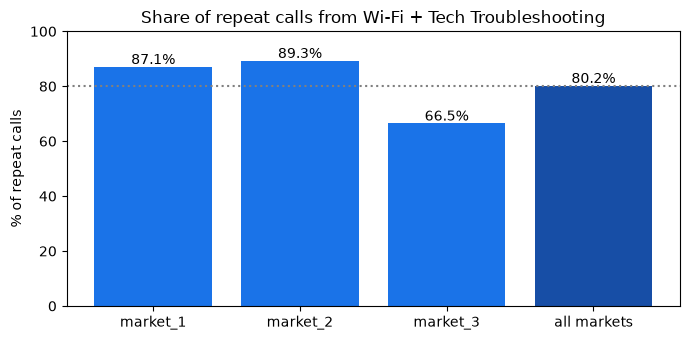

market
market_1       87.1
market_2       89.3
market_3       66.5
all markets    80.2
Name: repeat_calls, dtype: float64

In [2]:
mc = fcr.summary_by_market(df, by_category=True)
mc['wifi_tech'] = mc.problem_category.isin(['Wi-Fi & Internet', 'Technical Troubleshooting'])
share = (mc[mc.wifi_tech].groupby('market').repeat_calls.sum() / mc.groupby('market').repeat_calls.sum() * 100).round(1)
share['all markets'] = round(mc[mc.wifi_tech].repeat_calls.sum() / mc.repeat_calls.sum() * 100, 1)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(share.index, share.values, color=['#1a73e8']*3 + ['#174ea6'])
for i, v in enumerate(share.values): ax.text(i, v + 1, f'{v}%', ha='center')
ax.axhline(80, ls=':', color='gray'); ax.set_ylim(0, 100); ax.set_ylabel('% of repeat calls')
ax.set_title('Share of repeat calls from Wi-Fi + Tech Troubleshooting'); plt.tight_layout()
fig.savefig(FIG / 'wifi_tech_share_by_market.png', dpi=150); plt.show(); share

## Repeat rate by category
Billing shows the highest rate overall (67.5%), but see the market_3 caveat below. Scheduling is next at 60.6%.

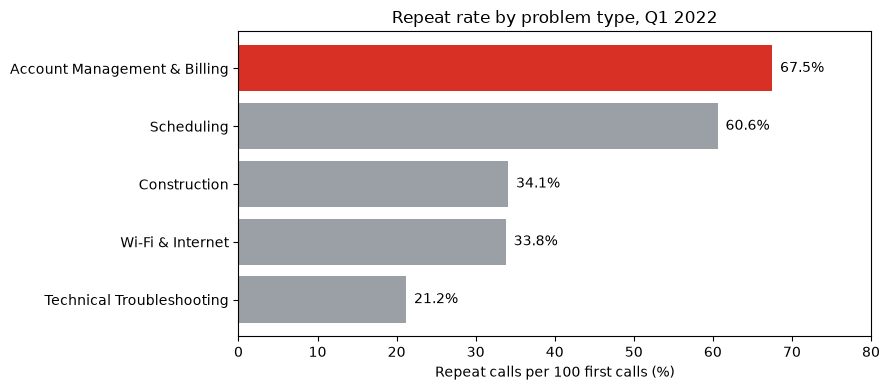

In [3]:
c = cat.sort_values('repeat_rate_pct')
fig, ax = plt.subplots(figsize=(9, 4))
cols = ['#d93025' if x == 'Account Management & Billing' else '#9aa0a6' for x in c.problem_category]
ax.barh(c.problem_category, c.repeat_rate_pct, color=cols)
for y, v in enumerate(c.repeat_rate_pct): ax.text(v + 1, y, f'{v}%', va='center')
ax.set_xlabel('Repeat calls per 100 first calls (%)'); ax.set_title('Repeat rate by problem type, Q1 2022')
ax.set_xlim(0, 80); plt.tight_layout(); fig.savefig(FIG / 'repeat_rate_by_category.png', dpi=150); plt.show()

## 2. Where repeat volume comes from
Wi-Fi & Internet plus Technical Troubleshooting account for ~80% of repeat calls, mostly because they have far more first calls.

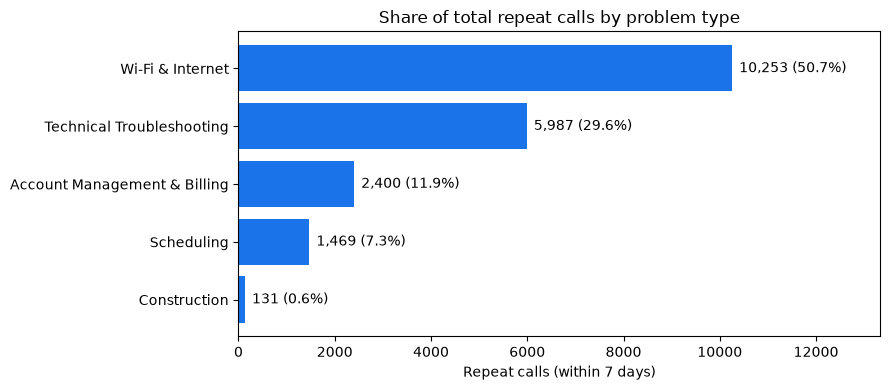

Wi-Fi + Tech share of repeats: 80.2%


In [4]:
c = cat.sort_values('repeat_calls')
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(c.problem_category, c.repeat_calls, color='#1a73e8')
for y, (v, s) in enumerate(zip(c.repeat_calls, c.pct_of_total_repeats)): ax.text(v + 150, y, f'{v:,} ({s}%)', va='center')
ax.set_xlabel('Repeat calls (within 7 days)'); ax.set_title('Share of total repeat calls by problem type')
ax.set_xlim(0, c.repeat_calls.max() * 1.3); plt.tight_layout(); fig.savefig(FIG / 'repeat_volume_by_category.png', dpi=150); plt.show()
two = cat.set_index('problem_category').loc[['Wi-Fi & Internet','Technical Troubleshooting'],'repeat_calls'].sum()
print(f'Wi-Fi + Tech share of repeats: {two / cat.repeat_calls.sum():.1%}')

## 3. By market

,market,first_calls,repeat_calls,repeat_rate_pct,fcr_pct
0,market_1,45333,12647,27.9,72.1
1,market_2,4389,787,17.9,82.1
2,market_3,15217,6806,44.7,55.3


market,market_1,market_2,market_3
problem_category,,,
Account Management & Billing,33.9,17.9,197.4
Construction,33.5,40.0,35.0
Scheduling,51.1,31.2,75.9
Technical Troubleshooting,21.3,15.4,25.0
Wi-Fi & Internet,34.1,19.8,35.9


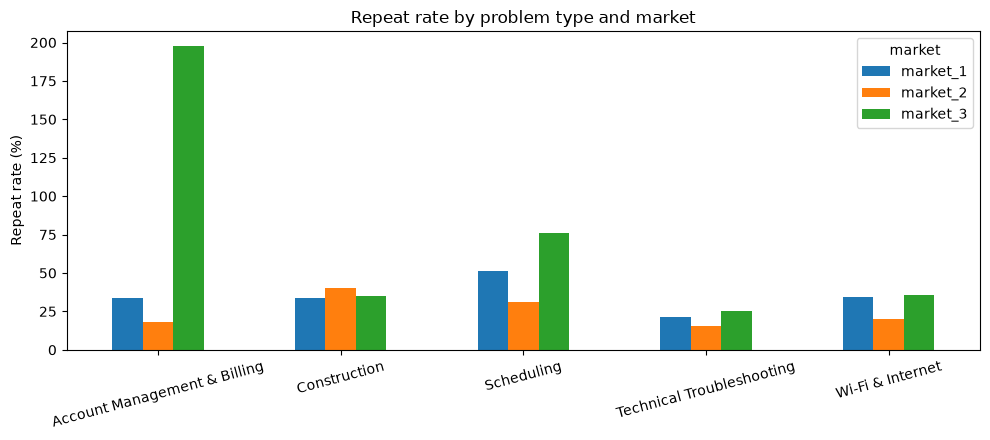

In [5]:
mkt = fcr.summary_by_market(df); display(mkt)
mc = fcr.summary_by_market(df, by_category=True)
piv = mc.pivot(index='problem_category', columns='market', values='repeat_rate_pct'); display(piv)
ax = piv.plot.bar(figsize=(10, 4.5), rot=15); ax.set_ylabel('Repeat rate (%)'); ax.set_xlabel('')
ax.set_title('Repeat rate by problem type and market'); plt.tight_layout()
plt.savefig(FIG / 'repeat_rate_by_market.png', dpi=150); plt.show()

## 4. Weekly trend

,week,first_calls,repeat_calls,repeat_rate_pct,fcr_pct,wow_repeat_rate_change_pts
0,2021-12-27,782,227,29.0,71.0,NaN
1,2022-01-03,5147,1504,29.2,70.8,0.2
2,2022-01-10,4933,1231,25.0,75.0,-4.2
3,2022-01-17,4547,1352,29.7,70.3,4.7
4,2022-01-24,4941,1653,33.5,66.5,3.8
5,2022-01-31,4472,1478,33.1,66.9,-0.4
6,2022-02-07,4742,1736,36.6,63.4,3.5
7,2022-02-14,5174,1696,32.8,67.2,-3.8
8,2022-02-21,4778,1501,31.4,68.6,-1.4
9,2022-02-28,5342,1724,32.3,67.7,0.9


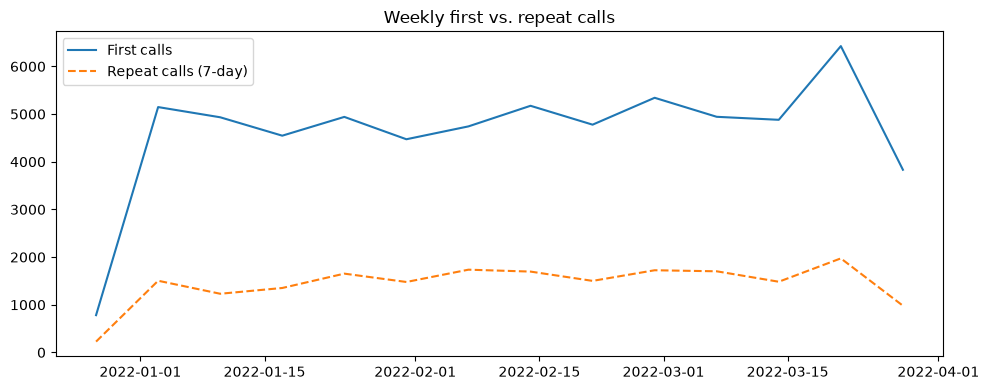

In [6]:
wk = fcr.weekly_trend(df); display(wk)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(wk.week, wk.first_calls, label='First calls'); ax.plot(wk.week, wk.repeat_calls, '--', label='Repeat calls (7-day)')
ax.set_title('Weekly first vs. repeat calls'); ax.legend(); plt.tight_layout()
fig.savefig(FIG / 'weekly_trend.png', dpi=150); plt.show()

## 5. SQL cross-check (DuckDB)
`sql/fcr_metrics.sql` computes the same metrics with CTEs; `tests/test_sql_matches_python.py` asserts they match.

## Billing, reported two ways
* **Overall: 67.5%** (2,400 repeats / 3,553 first calls), the highest category rate.
* **Without market_3: 32.3%** (902 / 2,794), in line with the other categories.

In market_3, Billing records **1,498 repeats against 759 first calls**. If repeats are follow-ups to first calls (each of the 1–7-day buckets counting callbacks from that day's first calls), this is close to impossible at this scale. It points to a likely **data-quality or category-mapping issue** to investigate (for example, type codes mapped differently in market_3, or repeats attributed to the wrong category) before drawing conclusions about Billing.

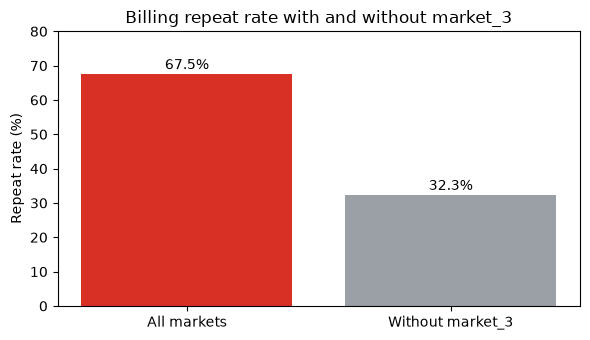

,market,problem_category,first_calls,repeat_calls,repeat_rate_pct,fcr_pct
0,market_1,Account Management & Billing,2504,850,33.9,66.1
5,market_2,Account Management & Billing,290,52,17.9,82.1
10,market_3,Account Management & Billing,759,1498,197.4,-97.4


In [7]:
b = mc[mc.problem_category == 'Account Management & Billing']
ex3 = b[b.market != 'market_3'][['first_calls','repeat_calls']].sum()
vals = {'All markets': round(b.repeat_calls.sum()/b.first_calls.sum()*100,1),
        'Without market_3': round(ex3.repeat_calls/ex3.first_calls*100,1)}
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(vals.keys(), vals.values(), color=['#d93025', '#9aa0a6'])
for i, v in enumerate(vals.values()): ax.text(i, v + 1.5, f'{v}%', ha='center')
ax.set_ylim(0, 80); ax.set_ylabel('Repeat rate (%)'); ax.set_title('Billing repeat rate with and without market_3')
plt.tight_layout(); fig.savefig(FIG / 'billing_with_without_market3.png', dpi=150); plt.show(); b

## Market_3 needs a closer look
Market_3 has the **highest overall repeat rate, 44.7%** (6,806 / 15,217), against 27.9% in market_1 and 17.9% in market_2. It also has the highest Scheduling rate (75.9%) and contains the Billing anomaly. Recommendation: audit market_3's data pipeline and category mapping first, then look at its operations.

## Findings & suggestions
1. **Wi-Fi + Tech Troubleshooting drive ~80% of repeat calls** (80.2% overall; 87.1% / 89.3% / 66.5% by market). That makes them the biggest volume lever, so pilot better first-call diagnostics and measure the effect on callbacks.
2. **Billing: 67.5% overall, 32.3% without market_3.** Investigate market_3 billing data before treating Billing as a problem area.
3. **Market_3 has the highest repeat rate (44.7%)** and should get a closer look.
4. Scheduling: 60.6% (1,469 / 2,424) is a high rate everywhere except market_2. Test giving customers appointment-status visibility.

Weekly repeats move with first-call volume, which is a correlation and not proof of cause. The data has no call reasons, customer IDs or costs, so these are hypotheses to test.